# 04 · The style × quarter table

One row per **style** per **quarter**, with that quarter's **success score** as the target.
This is the base table for modelling. Features will be added to it in the next step.

- Quarters: Spring (Mar–May), Summer (Jun–Aug), Autumn (Sep–Nov), Winter (Dec–Feb).
- Data up to **31 Aug 2020** → 8 complete quarters, Autumn 2018 (from 20 Sep) to Summer 2020.
  The prediction quarter, Autumn 2020, has no outcome; the 22 days of September 2020 in the data are held out.
- Every style in the catalogue gets a row for every quarter. A style with no sales in a quarter has success score 0.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_science").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_science.data import load_articles, load_transactions, CACHE_DIR
from data_science.features.style import add_style_columns
from data_science.features.quarters import quarters_between, build_style_quarter_table

pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 70)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

LAST_TRAINING_DAY = pd.Timestamp("2020-08-31")

styled = add_style_columns(load_articles())
tx = load_transactions(columns=["t_dat", "article_id", "price"])
tx = tx[tx.article_id.isin(styled.article_id) & (tx.t_dat <= LAST_TRAINING_DAY)]
quarters = quarters_between(tx.t_dat.min(), LAST_TRAINING_DAY)
quarters

,quarter_id,season,start,end
0,2018_autumn,autumn,2018-09-01,2018-11-30
1,2018_winter,winter,2018-12-01,2019-02-28
2,2019_spring,spring,2019-03-01,2019-05-31
3,2019_summer,summer,2019-06-01,2019-08-31
4,2019_autumn,autumn,2019-09-01,2019-11-30
5,2019_winter,winter,2019-12-01,2020-02-29
6,2020_spring,spring,2020-03-01,2020-05-31
7,2020_summer,summer,2020-06-01,2020-08-31


In [2]:
table = build_style_quarter_table(tx, styled, quarters)
table.to_parquet(CACHE_DIR / "style_quarters.parquet", index=False)
print(f"{len(table):,} rows = {table.style_id.nunique():,} styles × {table.quarter_id.nunique()} quarters")
table.dtypes.to_frame("dtype").T

188,072 rows = 23,509 styles × 8 quarters


,style_id,style_name,group_id,group_name,index_group_name,product_type_name,graphical_appearance_name,colour_group_name,perceived_colour_value_name,quarter_id,season,start,end,days_observed,success_score,revenue,full_price_factor,units,articles,sold
dtype,object,object,object,object,object,object,object,object,object,object,object,datetime64[ns],datetime64[ns],int64,float32,float32,float32,float64,float64,bool


## A few rows

In [3]:
cols = ["style_id", "quarter_id", "success_score", "revenue", "full_price_factor", "units", "articles", "sold"]
examples = ["ladieswear__trousers__solid__black__dark",
            "ladieswear__swimwear-bottom__solid__black__dark",
            "ladieswear__coat__solid__black__dark"]
table.loc[table.style_id.isin(examples), cols].round(3)

,style_id,quarter_id,success_score,revenue,full_price_factor,units,articles,sold
107984,ladieswear__coat__solid__black__dark,2018_autumn,1.919,420.209991,0.921,3977.0,23.0,True
107985,ladieswear__coat__solid__black__dark,2018_winter,1.893,179.177994,0.779,2171.0,23.0,True
107986,ladieswear__coat__solid__black__dark,2019_spring,1.539,145.436005,0.872,1698.0,19.0,True
107987,ladieswear__coat__solid__black__dark,2019_summer,2.679,76.574997,0.879,705.0,16.0,True
107988,ladieswear__coat__solid__black__dark,2019_autumn,2.869,754.859985,0.892,6518.0,24.0,True
107989,ladieswear__coat__solid__black__dark,2019_winter,2.856,198.492996,0.645,2576.0,28.0,True
107990,ladieswear__coat__solid__black__dark,2020_spring,2.277,32.644001,0.694,374.0,21.0,True
107991,ladieswear__coat__solid__black__dark,2020_summer,1.554,17.087000,0.700,166.0,17.0,True
141968,ladieswear__swimwear-bottom__solid__black__dark,2018_autumn,2.177,114.342003,0.713,9182.0,57.0,True
141969,ladieswear__swimwear-bottom__solid__black__dark,2018_winter,2.336,402.023987,0.868,21964.0,63.0,True


In [4]:
print("a random sample of rows:")
table.sample(8, random_state=3)[["style_name", "quarter_id", "success_score", "revenue", "units", "articles", "sold"]].round(3)

a random sample of rows:


,style_name,quarter_id,success_score,revenue,units,articles,sold
124490,Ladieswear · Pyjama jumpsuit/playsuit · All over pattern · Dark Bl...,2019_spring,1.179,8.715,352.0,1.0,True
29524,Baby/Children · Other accessories · Solid · Black · Dark,2019_autumn,2.356,1.298,71.0,10.0,True
154009,Ladieswear · Wallet · Mixed solid/pattern · Dark Red · Dark,2018_winter,0.000,0.000,0.0,0.0,False
107558,Ladieswear · Cardigan · Solid · Pink · Medium,2020_spring,0.067,1.862,48.0,1.0,True
153164,Ladieswear · Vest top · Sequin · Light Beige · Dusty Light,2019_autumn,0.088,8.436,310.0,2.0,True
81161,Divided · Scarf · Solid · Grey · Medium Dusty,2018_winter,0.067,1.268,94.0,1.0,True
66051,Baby/Children · Vest top · Mixed solid/pattern · Grey · Dusty Light,2019_summer,0.004,0.015,2.0,1.0,True
174555,Menswear · T-shirt · Solid · Grey · Medium Dusty,2019_summer,0.000,0.000,0.0,0.0,False


## The target per quarter

In [5]:
per_q = table.groupby("quarter_id", sort=False).agg(
    days=("days_observed", "first"),
    styles_sold=("sold", "sum"),
    share_sold=("sold", "mean"),
    mean_score_if_sold=("success_score", lambda s: s[s > 0].mean()),
    p90_score=("success_score", lambda s: s.quantile(.9)),
    max_score=("success_score", "max"),
)
per_q.style.format({"styles_sold": "{:,}", "share_sold": "{:.0%}", "mean_score_if_sold": "{:.2f}",
                    "p90_score": "{:.2f}", "max_score": "{:.2f}"})

,days,styles_sold,share_sold,mean_score_if_sold,p90_score,max_score
quarter_id,,,,,,
2018_autumn,72,"12,459",53%,0.16,0.20,4.28
2018_winter,90,"12,923",55%,0.17,0.22,4.05
2019_spring,92,"13,006",55%,0.18,0.25,4.17
2019_summer,92,"12,740",54%,0.18,0.24,3.84
2019_autumn,91,"12,117",52%,0.17,0.20,4.25
2019_winter,91,"12,577",53%,0.17,0.22,4.49
2020_spring,92,"11,991",51%,0.19,0.25,4.28
2020_summer,92,"12,718",54%,0.18,0.24,4.75


in how many of the 8 quarters does a style sell?


sold      0     1     2     3     4     5     6     7     8
styles  514  2851  3759  3383  2761  2328  2141  1693  4079


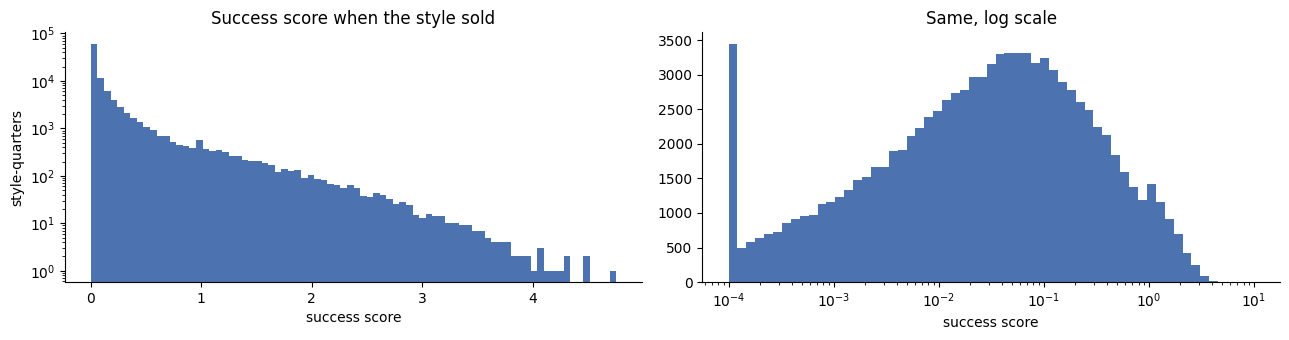

In [6]:
sold_quarters = table.groupby("style_id").sold.sum()
print("in how many of the 8 quarters does a style sell?")
print(sold_quarters.value_counts().sort_index().rename("styles").to_frame().T.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].hist(table.loc[table.sold, "success_score"], bins=80, color="#4C72B0")
axes[0].set(title="Success score when the style sold", xlabel="success score", ylabel="style-quarters", yscale="log")
axes[1].hist(table.loc[table.sold, "success_score"].clip(lower=1e-4), bins=np.logspace(-4, 1, 60), color="#4C72B0")
axes[1].set(title="Same, log scale", xlabel="success score", xscale="log")
plt.tight_layout(); plt.show()

In [7]:
# top 3 per quarter: the "answer" we would have wanted the model to give for each past quarter
top3 = (table.sort_values("success_score", ascending=False).groupby("quarter_id", sort=False).head(3)
        .sort_values(["start", "success_score"], ascending=[True, False]))
top3[["quarter_id", "style_name", "success_score", "revenue", "articles"]].round(2)

,quarter_id,style_name,success_score,revenue,articles
87800,2018_autumn,Divided · Sweater · Solid · Black · Dark,4.28,632.349976,105.0
139072,2018_autumn,Ladieswear · Sweater · Solid · Black · Dark,3.80,1914.010010,145.0
170968,2018_autumn,Menswear · Sweater · Solid · Black · Dark,3.69,204.300003,75.0
139073,2018_winter,Ladieswear · Sweater · Solid · Black · Dark,4.05,982.099976,133.0
46217,2018_winter,Baby/Children · Sweater · All over pattern · Grey · Dusty Light,4.04,35.730000,28.0
87801,2018_winter,Divided · Sweater · Solid · Black · Dark,3.90,483.470001,129.0
133274,2019_spring,Ladieswear · Skirt · Solid · Black · Dark,4.17,400.209991,99.0
111490,2019_spring,Ladieswear · Dress · Solid · Black · Dark,3.97,2507.320068,379.0
170970,2019_spring,Menswear · Sweater · Solid · Black · Dark,3.80,49.619999,61.0
133275,2019_summer,Ladieswear · Skirt · Solid · Black · Dark,3.84,491.700012,107.0
